# Zonal minimum age in density-latitude space

Related issue: https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/117

Objective: plot zonal minimum age in density (rho0)-latitude space in a new script based on temp-salt-vs-depth-latitude.ipynb.

In [1]:
# These first two cells must be in all notebooks!
# It allows us to run all the notebooks at once, this cell has a tag "parameters" which allows us to pass in 
# arguments externally using papermill (see mkfigs.sh for details)

# Set esm_file to the datastore for the main experiment of interest
esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test4-d28e0359/datastore.json"

# papermill settings. *No need to modify these if running interactively.* 
papermill = False                      # `cwd` and `nbname` will be populated by papermill.
cwd = None                             # current working directory 
nbname = "minimum-age-density-latitude.ipynb"        # notebook name

In [2]:
if not papermill: 
    import nci_ipynb, os  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
    
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter
mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)
#from model_agnostic import patch_broken_conda_env
from exptdata_access import guess_experiment_from_esm_file
#patch_broken_conda_env()  # conda env workaround for analysis3-26.03+; no-op on healthy envs
expt_key, info = guess_experiment_from_esm_file(esm_file)
model_name = info["model"]  # OM3 or CM3

In [3]:
IAF = esm_file.find('iaf') > 0
IAF

True

In [4]:
import os
import numpy as np
import xarray as xr
import cftime
import cf_xarray as cfxr
import cf_xarray.units
import pint_xarray
from pint import application_registry as ureg
import gsw
import intake
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import matplotlib as mpl
from distributed import Client
import cmocean
import cartopy.crs as ccrs
import cartopy.feature as cft
from shapely import geometry
from textwrap import wrap
from tqdm.notebook import tqdm
xr.set_options(keep_attrs=True);  # cf_xarray works best when xarray keeps attributes by default

In [5]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [6]:
client = Client(threads_per_worker=1)
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /proxy/8787/status,
Dashboard: /proxy/8787/status,Workers: 28
Total threads: 28,Total memory: 125.19 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:43913,Workers: 0
Dashboard: /proxy/8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:41515,Total threads: 1
Dashboard: /proxy/36159/status,Memory: 4.47 GiB
Nanny: tcp://127.0.0.1:33351,


Global maxy changed from 90 to 65 to omit tripolar region


Text(0.5, 1.0, 'Regions (BUG: incorrect shapes north of 65°N)')

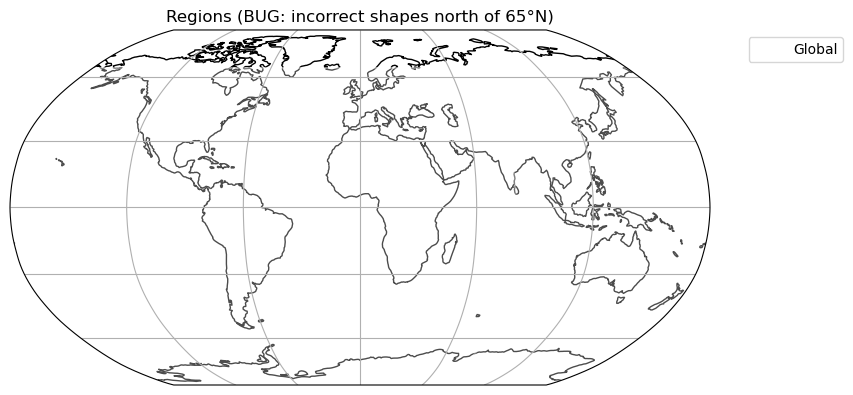

In [7]:
regions = { # [minx, maxx, miny, maxy], using model longitude range (-280 to 80)
    "Global": [-280, 80, -90, 90],
    # "Arctic": [-280, 80, 65, 90],
    # "Southern Ocean": [-280, 80, -82, -63],
    # "ACC": [-280, 80, -63, -45],
    # "Southern Pacific": [-210, -70, -45, -20],
    # "Tropical Pacific": [-240, -100, -20, 20],
    # "North Pacific": [-240, -100, 20, 65],
    # "South Atlantic": [-60, 20, -45, -20],
    # "Tropical Atlantic": [-70, 20, -20, 20],
    # "North Atlantic": [-100, 0, 20, 65],
    # "Indian": [30, 120, -45, 20],
    # "Aegean Sea": [18, 27.5, 34, 44],
    # "Black Sea": [27.5, 43, 40.5, 48],
    # "Baltic Sea": [13, 30, 53, 58],
    # "Mediterranean Sea": [0, 35, 31, 41],
    # "Red Sea": [33, 44, 12, 29],
    # "Persian Gulf": [47, 56, 24, 31],
    # "White Sea": [31, 41, 63, 68],
}
regions = {k: dict(zip(["minx", "maxx", "miny", "maxy"], v)) for k, v in regions.items()}  # convert to dicts

for r, d in regions.items():
    for k, x in d.items():
        if k in ["minx", "maxx"] and x != max(-280, min(x, 80)):
            raise ValueError(f"{r} {k} = {x} is outside the range -280 to 80")
        if k in ["miny", "maxy"] and x > 65:
            print(f"{r} {k} changed from {x} to 65 to omit tripolar region")
            d[k] = 65
            

fig = plt.figure(figsize=(10, 4))

colors = mpl.color_sequences['tab20']
try:  # set Global color to white 
    colors[list(regions.keys()).index("Global")] = (1, 1, 1)
except ValueError:
    pass

ax = plt.axes(position=[0.05,0.05,0.7,0.9], projection=ccrs.Robinson())
ax.coastlines(resolution="110m")
ax.gridlines(draw_labels=False)

legend_elements = []
for i, (region, limits) in enumerate(regions.items()):
    ax.add_geometries([geometry.box(**limits)], crs=ccrs.PlateCarree(), color=colors[i], alpha=0.3)
    legend_elements.append(Patch(color=colors[i], alpha=0.3, label=region))

ax.legend(handles=legend_elements, bbox_to_anchor=(1.2, 1.00))
plt.title("Regions (BUG: incorrect shapes north of 65°N)")

In [8]:
from exptdata_access import get_exptname_from_path
om3exptname = get_exptname_from_path(esm_file)

In [9]:
catalogs = [esm_file]
catalogs

['/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test4-d28e0359/datastore.json']

## Load OM3 data

In [10]:
om3datastores = { get_exptname_from_path(c):
               intake.open_esm_datastore(c,
                                         columns_with_iterables=[
                                            "variable",
                                            "variable_long_name",
                                            "variable_standard_name",
                                            "variable_cell_methods",
                                            "variable_units"]
                                        )
              for c in catalogs }
om3datastores

{'MC_25km_jra_iaf+wombatlite-test4-d28e0359': <datastore catalog with 24 dataset(s) from 32795 asset(s)>}

In [11]:
om3varnames = [ 'agessc','rhopot0']  # ideal age, density in rho0

om3vars = {
    vname: {expt: ds.search(variable=vname).to_dask(
                xarray_open_kwargs = dict(
                    chunks={"xh": -1, "yh": "auto", "z_l": "auto"},
                    decode_timedelta=True
                )
            )[vname]
            for expt, ds in om3datastores.items()
          }
    for vname in om3varnames
    }

# omit latitudes with grid bug in this run https://github.com/ACCESS-NRI/ocean_model_grid_generator/issues/7
for vname, d in om3vars.items():
    try:
        d['25km-iaf-test-for-AK-expt-7df5ef4c'] = d['25km-iaf-test-for-AK-expt-7df5ef4c'].isel(yh=slice(10, None))
    except ValueError:
        d['25km-iaf-test-for-AK-expt-7df5ef4c'] = d['25km-iaf-test-for-AK-expt-7df5ef4c'].isel(yq=slice(10, None))
    except KeyError:
        pass

if IAF or "cm3" in om3exptname.lower():  # common calendar for obs overlays
    for vname, d in om3vars.items():
        for expt in d:
            try:
                d[expt] = d[expt].convert_calendar("proleptic_gregorian", use_cftime=True)
            except KeyError:
                pass

## Load OM2 data

In [12]:
if model_name == "ACCESS-CM3":
    data_name = 'ACCESS-CM2'
    om2exptname = 'cj877'  # CM2 control archive on /g/data/p73 (same reference as pPV.ipynb)
else:
    data_name = 'ACCESS-OM2'
    if IAF:
        om2exptname = '025deg_jra55_iaf_omip2_cycle1'
    else:
        om2exptname = '025deg_jra55_ryf9091_gadi'  # monthly temp only for 1900-1903, and 2300-, with annual data in the gap
    om2datastores = {om2exptname: intake.cat.access_nri[om2exptname]}

In [13]:
if model_name == "ACCESS-CM3":
    # Reference: ACCESS-CM2 cj877 control archive (same source as pPV.ipynb,
    # Overturning_in_ACCESS_OM3.ipynb, and temp-salt-vs-depth-time.ipynb).
    # Limit to the last 600 months to match the CM3 record length; each
    # cj877 file holds 6 months.
    from pathlib import Path
    cm2_dir = Path("/g/data/p73/archive/non-CMIP/ACCESS-CM2/cj877/history/ocn")
    n_months = 600
    om2varnames = ['age_global', 'pot_rho_0']

    def _load_cm2(varname):
        files = sorted(cm2_dir.glob(f"ocean-3d-{varname}-1-monthly-mean-ym_*.nc"))
        if not files:
            raise FileNotFoundError(f"No cj877 monthly files found for {varname!r}")
        files = files[-((n_months + 5) // 6):]
        ds = xr.open_mfdataset(
            files,
            combine="by_coords",
            parallel=True,
            chunks={"time": 1, "xt_ocean": -1, "yt_ocean": -1, "st_ocean": -1},
            decode_timedelta=True,
            use_cftime=True,  # cj877 model years can't be datetime64
            data_vars="minimal", coords="minimal", compat="override",
        )
        return ds[varname]

    om2vars = { vname: {om2exptname: _load_cm2(vname)} for vname in om2varnames }
else:
    om2varnames = ['age_global', 'pot_rho_0']  

    om2vars = {
        vname: {expt: ds.search(variable=vname, frequency="1mon").to_dask(
                    xarray_open_kwargs = dict(
                        chunks={"xt_ocean": -1, "yt_ocean": "auto", "st_ocean" : "auto"},
                        decode_timedelta=True
                    )
                )[vname]
                for expt, ds in om2datastores.items()
              }
        for vname in om2varnames
        }

    if IAF:
        for vname, d in om2vars.items():
            for expt in d:
                try:
                    d[expt] = d[expt].convert_calendar("proleptic_gregorian", use_cftime=True)
                except KeyError:
                    pass

## Set time range

In [14]:
lasttime = []
for vname, d in om3vars.items():
    for expt, da in d.items():
        lasttime.append(da.time.values[-1])
for vname, d in om2vars.items():
    for expt, da in d.items():
        lasttime.append(da.time.values[-1])

if IAF or "cm3" in om3exptname.lower():  # robust window relative to the data's own last timestep
    # datestop = cftime.DatetimeProlepticGregorian(2018, 12, 31, 12, 0, 0, 0, has_year_zero=True)  # to match OM2 IAF run
    datestop = min(lasttime) # earliest final date in data
    datelist = list(cftime.to_tuple(datestop))
    datelist[0] -= 25  # last 25 years
    datestart = cftime.datetime(*datelist, calendar=datestop.calendar)
    # bracket to start/end of year
    datestart = cftime.datetime(cftime.to_tuple(datestart)[0],  1, 1, calendar=datestop.calendar)
    datestop  = cftime.datetime(cftime.to_tuple(datestop)[0], 12, 31, 23, 59, 59, calendar=datestop.calendar)
    timerange = slice(datestart, datestop)
else:
    timerange = slice(cftime.DatetimeNoLeap(1932, 1, 1, 0, 0, 0, 0),
                      cftime.DatetimeNoLeap(1952, 1, 1, 0, 0, 0, 0))

# timerange = slice(None, None)

timerange

slice(cftime.datetime(1993, 1, 1, 0, 0, 0, 0, calendar='proleptic_gregorian', has_year_zero=True), cftime.datetime(2018, 12, 31, 23, 59, 59, 0, calendar='proleptic_gregorian', has_year_zero=True), None)

## Putting age on density coordinates

In [24]:
rho0_bin_edges = np.arange(1020.0, 1028.3, 0.05)   # extend past 1028 to catch the densest water
rho0_bin_centers = 0.5 * (rho0_bin_edges[:-1] + rho0_bin_edges[1:])

Note: the below gives the youngest time-mean age found in each density class at each latitude. Do we want the youngest age that occurs at any time instead - aka what is set by winter MLD extremes? 

In [25]:
def zonal_min_age_density(age_da, rho_da, lat_dim, bins=rho0_bin_edges, min_count=5):
    """Zonal minimum age in density space, at each latitude.

    age_da, rho_da: DataArrays with matching dims (lat_dim, other spatial dims,
                     z-dim[, time]). 
    """
    ds = xr.Dataset({"age": age_da, "rho0": rho_da})

    def _min_in_bins(ds_slice):
        grouped = ds_slice["age"].groupby_bins(ds_slice["rho0"], bins=bins)
        counts = grouped.count()
        mins = grouped.min()
        return mins.where(counts >= min_count)

    result = ds.groupby(lat_dim).map(_min_in_bins)
    result = result.rename({"rho0_bins": "rho0_bin"})
    result = result.assign_coords(rho0_bin=rho0_bin_centers)
    return result

## Calculate zonal minimums

In [26]:
%%time
om3vars_mean = {
    region:
    {
        expt: zonal_min_age_density(
            om3vars['agessc'][expt]
                .sel(yh=slice(b['miny'], b['maxy']))
                .sel(xh=slice(b['minx'], b['maxx']))
                .sel(time=timerange)
                .mean('time'),
            om3vars['rhopot0'][expt]
                .sel(yh=slice(b['miny'], b['maxy']))
                .sel(xh=slice(b['minx'], b['maxx']))
                .sel(time=timerange)
                .mean('time'),
            lat_dim='yh',
        ).load()
        for expt in tqdm(om3vars['agessc'], desc=f'   {region} experiments')
    }
    for region, b in tqdm(regions.items(), desc='regions')
}

regions:   0%|          | 0/1 [00:00<?, ?it/s]

   Global experiments:   0%|          | 0/1 [00:00<?, ?it/s]

CPU times: user 3min 57s, sys: 2min 31s, total: 6min 28s
Wall time: 6min 45s


In [27]:
%%time
om2vars_mean = {
    region:
    {
        expt: zonal_min_age_density(
            om2vars['age_global'][expt]
                .sel(yt_ocean=slice(b['miny'], b['maxy']))
                .sel(xt_ocean=slice(b['minx'], b['maxx']))
                .sel(time=timerange)
                .mean('time'),
            om2vars['pot_rho_0'][expt]
                .sel(yt_ocean=slice(b['miny'], b['maxy']))
                .sel(xt_ocean=slice(b['minx'], b['maxx']))
                .sel(time=timerange)
                .mean('time'),
            lat_dim='yt_ocean',
        ).load()
        for expt in tqdm(om2vars['age_global'], desc=f'   {region} experiments')
    }
    for region, b in tqdm(regions.items(), desc='regions')
}

regions:   0%|          | 0/1 [00:00<?, ?it/s]

   Global experiments:   0%|          | 0/1 [00:00<?, ?it/s]

CPU times: user 3min 21s, sys: 2min 11s, total: 5min 32s
Wall time: 5min 9s


## Plotting

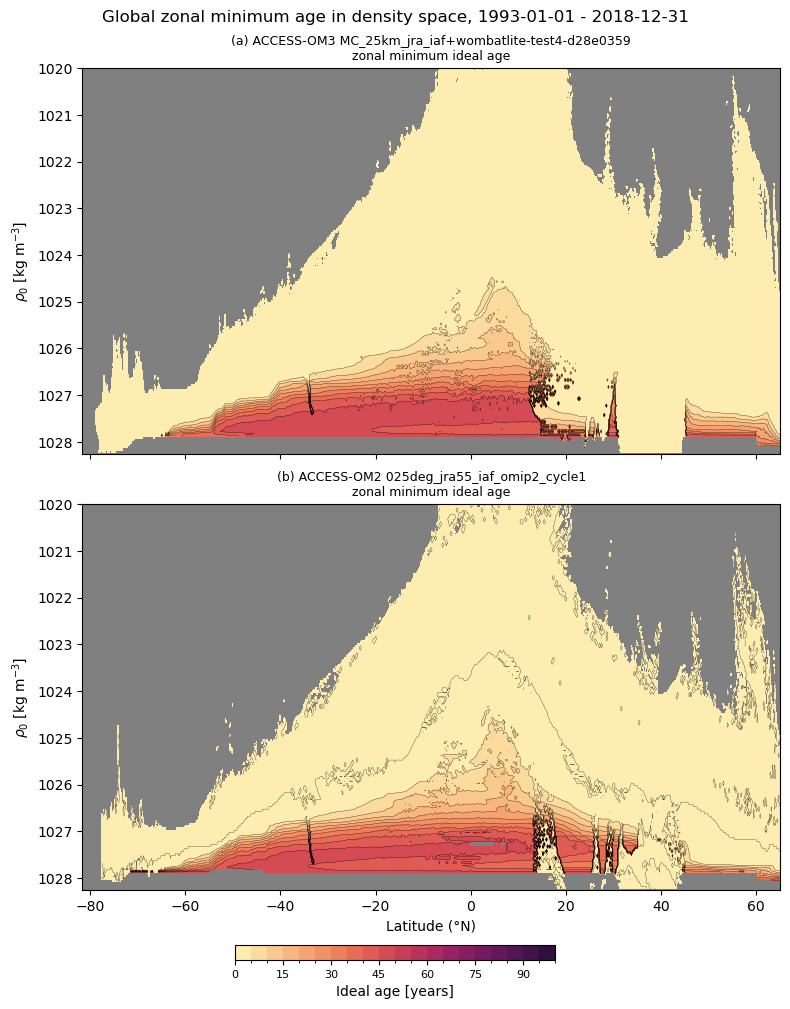

In [28]:
for region, d in om3vars_mean.items():
    npanels = len(d) + len(om2vars_mean[region])
    nrows = npanels
    fig, axs = plt.subplots(nrows, 1, figsize=(8, 5 * nrows), sharex=True, sharey=True)
    axs = np.atleast_1d(axs)
    fig.suptitle(
        f'{region} zonal minimum age in density space, '
        f'{timerange.start.strftime("%Y-%m-%d")} - {timerange.stop.strftime("%Y-%m-%d")}',
        y=0.98,
    )
    cmap = cmocean.cm.matter
    vmin, vmax = 0, 100  # ideal age [years] -- adjust to your region/depth range
    panel = 0

    levels = np.arange(0, 101, 5)
    
    # ACCESS-OM3 experiments
    for expt, da in d.items():
        ax = axs[panel]
        plt.sca(ax)
        ax.set_facecolor('gray')  # gray for empty (no data) bins
        p = da.plot.contourf(
            x='yh', y='rho0_bin', levels=levels, cmap=cmap, vmin=vmin, vmax=vmax, add_colorbar=False,
        )
        da.plot.contour(
            x='yh', y='rho0_bin', levels=levels, colors=['k'], linewidths=[0.2], add_colorbar=False,
        )
        ax.set_ylim([rho0_bin_edges[0], rho0_bin_edges[-1]])
        ax.invert_yaxis()
        ax.set_title(f"({chr(ord('a')+panel)}) ACCESS-OM3 {expt}\nzonal minimum ideal age", fontsize=9)
        ax.set_xlabel('')
        ax.set_ylabel(r'$\rho_0$ [kg m$^{-3}$]')
        panel += 1

    # ACCESS-OM2 experiments
    for expt, da in om2vars_mean[region].items():
        ax = axs[panel]
        plt.sca(ax)
        ax.set_facecolor('gray')
        p = da.plot.contourf(
            x='yt_ocean', y='rho0_bin', levels=levels, cmap=cmap, vmin=vmin, vmax=vmax, add_colorbar=False,
        )
        da.plot.contour(
            x='yt_ocean', y='rho0_bin', levels=levels, colors=['k'], linewidths=[0.2], add_colorbar=False,
        )
        ax.set_ylim([rho0_bin_edges[0], rho0_bin_edges[-1]])
        ax.invert_yaxis()
        ax.set_title(f"({chr(ord('a')+panel)}) {data_name} {expt}\nzonal minimum ideal age", fontsize=9)
        ax.set_xlabel('Latitude (°N)')
        ax.set_ylabel(r'$\rho_0$ [kg m$^{-3}$]')
        panel += 1

    for ax in fig.get_axes():
        ax.label_outer()
    plt.tight_layout()
    plt.subplots_adjust(bottom=0.1)
    cax = plt.axes([0.3, 0.03, 0.4, 0.015])
    cb = plt.colorbar(p, cax=cax, orientation='horizontal')
    cb.ax.tick_params(labelsize=8)
    cb.set_label('Ideal age [years]')

    # mkmd.savefig(fig, f"{region} zonal minimum age in density-latitude space",
    #              f"{region} zonal minimum ideal age vs density (rho0) and latitude, "
    #              "comparing ACCESS-OM3 and ACCESS-OM2. "
    #              "GitHub issue: https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/117",
    #              dpi=150)

Domain restriction:

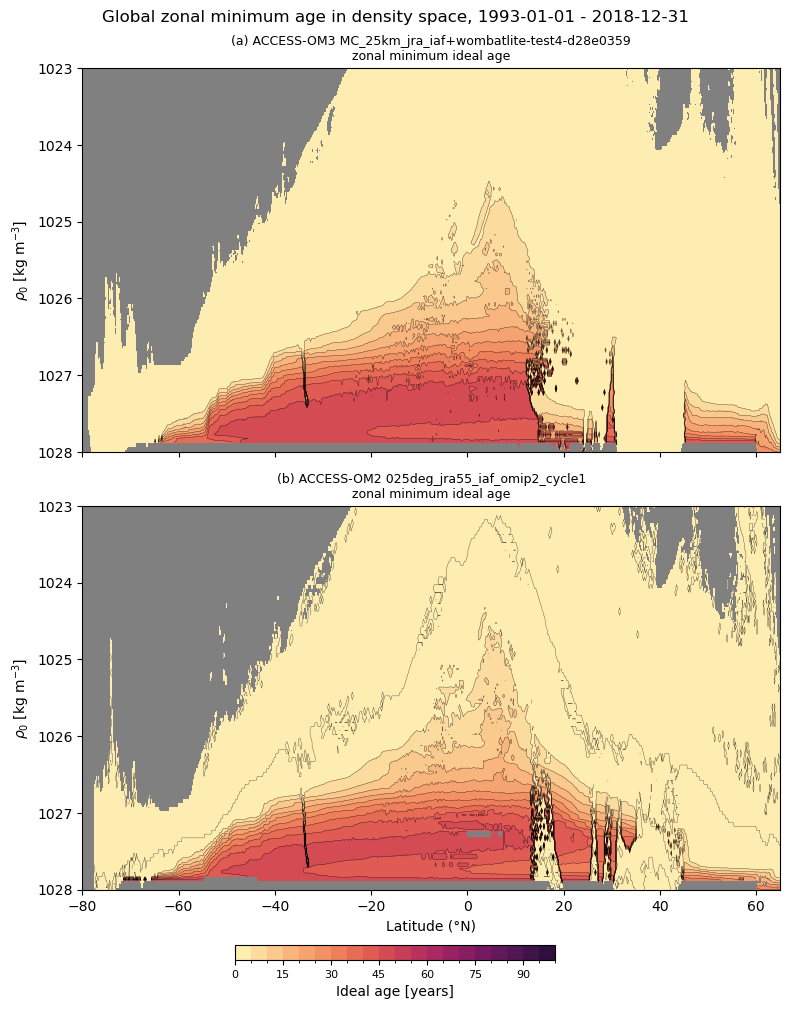

In [31]:
for region, d in om3vars_mean.items():
    npanels = len(d) + len(om2vars_mean[region])
    nrows = npanels
    fig, axs = plt.subplots(nrows, 1, figsize=(8, 5 * nrows), sharex=True, sharey=True)
    axs = np.atleast_1d(axs)
    fig.suptitle(
        f'{region} zonal minimum age in density space, '
        f'{timerange.start.strftime("%Y-%m-%d")} - {timerange.stop.strftime("%Y-%m-%d")}',
        y=0.98,
    )
    cmap = cmocean.cm.matter
    vmin, vmax = 0, 100  # ideal age [years] -- adjust to your region/depth range
    panel = 0

    xlim = -80, None
    ylim = 1028,1023
    
    levels = np.arange(0, 101, 5)
    
    # ACCESS-OM3 experiments
    for expt, da in d.items():
        ax = axs[panel]
        plt.sca(ax)
        ax.set_facecolor('gray')  # gray for empty (no data) bins
        p = da.plot.contourf(
            x='yh', y='rho0_bin', levels=levels, cmap=cmap, vmin=vmin, vmax=vmax, add_colorbar=False,
        )
        da.plot.contour(
            x='yh', y='rho0_bin', levels=levels, colors=['k'], linewidths=[0.2], add_colorbar=False,
        )
        ax.set_ylim([rho0_bin_edges[0], rho0_bin_edges[-1]])
        ax.invert_yaxis()
        ax.set_title(f"({chr(ord('a')+panel)}) ACCESS-OM3 {expt}\nzonal minimum ideal age", fontsize=9)
        ax.set_xlabel('')
        ax.set_xlim(xlim)
        ax.set_ylim(ylim)
        ax.set_ylabel(r'$\rho_0$ [kg m$^{-3}$]')
        panel += 1

    # ACCESS-OM2 experiments
    for expt, da in om2vars_mean[region].items():
        ax = axs[panel]
        plt.sca(ax)
        ax.set_facecolor('gray')
        p = da.plot.contourf(
            x='yt_ocean', y='rho0_bin', levels=levels, cmap=cmap, vmin=vmin, vmax=vmax, add_colorbar=False,
        )
        da.plot.contour(
            x='yt_ocean', y='rho0_bin', levels=levels, colors=['k'], linewidths=[0.2], add_colorbar=False,
        )
        ax.set_ylim([rho0_bin_edges[0], rho0_bin_edges[-1]])
        ax.invert_yaxis()
        ax.set_title(f"({chr(ord('a')+panel)}) {data_name} {expt}\nzonal minimum ideal age", fontsize=9)
        ax.set_xlabel('Latitude (°N)')
        ax.set_ylabel(r'$\rho_0$ [kg m$^{-3}$]')
        ax.set_xlim(xlim)
        ax.set_ylim(ylim)
        panel += 1

    for ax in fig.get_axes():
        ax.label_outer()
    plt.tight_layout()
    plt.subplots_adjust(bottom=0.1)
    cax = plt.axes([0.3, 0.03, 0.4, 0.015])
    cb = plt.colorbar(p, cax=cax, orientation='horizontal')
    cb.ax.tick_params(labelsize=8)
    cb.set_label('Ideal age [years]')

    mkmd.savefig(fig, f"{region} zonal minimum age in density-latitude space",
                 f"{region} zonal minimum ideal age vs density (rho0) and latitude, "
                 "comparing ACCESS-OM3 and ACCESS-OM2. "
                 "GitHub issue: https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/117",
                 dpi=150)

In [ ]:
client.close()